Import necessary pacakages and read data

In [2]:
import geopandas as gpd
import pandas as pd

# change this as needed (i don't know why it doesn't take relative paths and I'm too tired to look into it).
species = "camel_remains_reprojected"
file_path = f"c:\\Users\\vladu\\OneDrive\\Desktop\\geotracking_camelids_NINO_project\\map_project\\camel_data\\{species}.shp"

data = gpd.read_file(file_path)


View a sample

In [3]:
data.head()


,id,species_or,species_re,hybrid?,other_name,domestic_s,evidence_t,primary_so,NISP_.,NISP_%,direct_rad,date_old,date_young,date_other,site,comments,lat,long,crs,geometry
0,5,Camelus ferus,Camelus ferus,NaN,NaN,wild,iconography,rock art,NaN,NaN,NaN,NaN,-10000.0,Pleistocene,Khoid Tsenkher Cave,NaN,47.325167,91.973392,EPSG:4326,POINT (7429921.692 5711812.329)
1,10,Camelus,Camelus sp.,NaN,NaN,NaN,faunal remains,NaN,1.0,NaN,1.0,-1590.0,-1190.0,NaN,Azraq Oasis,NaN,31.834418,36.814906,EPSG:4326,POINT (3272445.146 3982071.91)
2,11,Camelus,Camelus sp.,NaN,NaN,NaN,faunal remains,NaN,1.0,NaN,1.0,820.0,960.0,NaN,Tabun Cave,NaN,32.670525,34.965507,EPSG:4326,POINT (3095376.655 4080562.113)
3,12,Camelus,Camelus sp.,NaN,NaN,NaN,faunal remains,NaN,1.0,NaN,1.0,990.0,1230.0,NaN,Mugharet-et-Emireh Cave,location of the cave approximated from random ...,32.865403,35.513929,EPSG:4326,POINT (3140880.25 4103447.476)
4,15,Camelus bactrianus,Camelus bactrianus,NaN,NaN,domestic,faunal remains,NaN,5.0,NaN,0.0,-2700.0,-2500.0,NaN,Shahr-e Sukhteh,NaN,30.595278,61.326392,EPSG:4326,POINT (5483199.136 3835228.592)


View graphical

<Axes: >

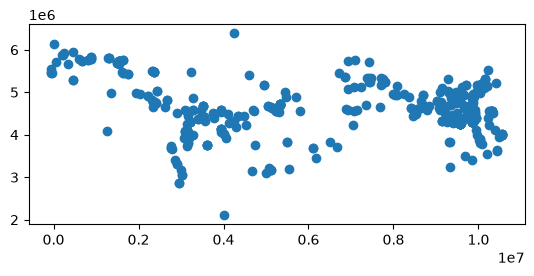

In [4]:
data.plot()


Determine filter for additive selection (keep adding to selection based on new filter element). Also export the filter vector as csv if I want to join it to another shapefile later.

In [5]:
# Pick which column becomes the filter.
filter_column = "date_old"
# Then make and sort the filter.
filter_vector = sorted(data[filter_column].dropna().unique())

filter_dataframe = {
  'int_id' : range(1, len(filter_vector) + 1),
  'filter_vector' : filter_vector
}

df = pd.DataFrame(filter_dataframe)
df
df.to_csv(
    rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\camel_data\{species}_years.csv"
)

Initialise output with the same structure as input and initialise a counter to use in file naming

In [6]:
output = data.iloc[0:0]  # empty dataframe with same columns

counter = 1


Then just loop over elements in the filter and keep adding and saving the current output from each iteration

In [7]:
for item in filter_vector:
    tmp = data[data[filter_column] == item]

    output = pd.concat([output, tmp], ignore_index=True)
    output = gpd.GeoDataFrame(output, geometry="geometry", crs=data.crs)

    output.to_file(
        rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\camel_data\{species}_{counter}.shp",
        driver="ESRI Shapefile",
    )

    counter += 1